# 61 · Carleman lift

**Question.** Does the Carleman lift give a nonlinear equation one ground state in both forms, how fast does it converge in its order, and how does its kernel compare with the paper's doubled space?

In [1]:
from pathlib import Path

from pihm import plotting
from pihm.pipeline.results import Results

results = Results.at(Path("..").resolve())
CAMPAIGNS = ("p6_build", "p6_stateprep", "p6_t3", "p2_reproduction")
plotting.apply_style()
print(results.describe(CAMPAIGNS))

p6_build: 374 records, 374 ok
p6_stateprep: 162 records, 162 ok
p6_t3: 140 records, 140 ok
p2_reproduction: 327 records, 327 ok


In [2]:
from IPython.display import Markdown, display


def rows(campaign, problem, **match):
    """Return a campaign's ok rows of a problem whose columns equal every match."""
    return [
        r
        for r in results.rows(campaign)
        if r["status"] == "ok"
        and r["problem"] == problem
        and all(r[k] == v for k, v in match.items())
    ]


builds = rows("p6_build", "R8", label="")
estimates = rows("p6_t3", "R8")
prepared = [r for r in rows("p6_stateprep", "R8") if not r["label"] and r["trusted"]]
finest = max(r["n"] for r in builds)
floors = {
    r["carleman"]: r["lift_err_linf"]
    for r in builds
    if r["n"] == finest and r["regime"] == "descriptor"
}
orders = sorted(floors)
ratios = [floors[k + 1] / floors[k] for k in orders[:-1]]
doubled = [r for r in results.rows("p2_reproduction") if r["problem"] in ("R6a", "R6b")]
doubled = [r for r in doubled if r["status"] == "ok" and r["variant"] == "corrected"]
lines = [
    f"- At n_t = {finest} the lift's error falls by {min(ratios):.2f}–{max(ratios):.2f} an "
    f"order from K = {orders[0]} to {orders[-1]}, against R = 1/2; the time axis adds at most "
    f"{max(r['axis_err_linf'] for r in builds if r['n'] == finest):.1e}.",
    f"- Every one of {len(builds)} builds has a one-dimensional kernel: "
    f"{all(r['kernel_dimension'] == 1 for r in builds)}. R6's doubled space leaves "
    f"{min(r['kernel_count'] for r in doubled)}–{max(r['kernel_count'] for r in doubled)}.",
    f"- {len(prepared)} trusted preparations in both forms, the worst infidelity "
    f"{max(r['infidelity'] for r in prepared):.1e}.",
]
display(Markdown("\n".join(lines)))

- At n_t = 8 the lift's error falls by 0.38–0.43 an order from K = 2 to 6, against R = 1/2; the time axis adds at most 1.1e-12.
- Every one of 60 builds has a one-dimensional kernel: True. R6's doubled space leaves 8–962.
- 60 trusted preparations in both forms, the worst infidelity 2.2e-13.

The field's error against the time axis's resolution, a line per Carleman order: each order's
error falls until the lift's own floor.

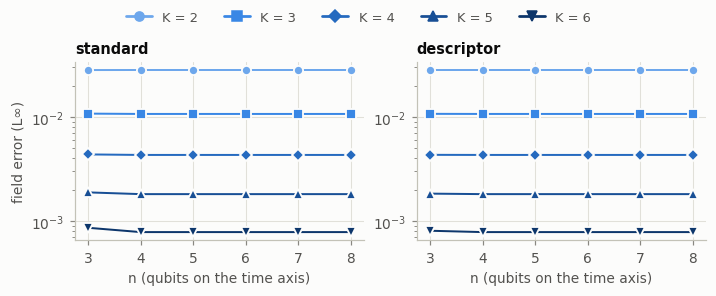

In [3]:
plotting.order_sweep(builds, "field_err_linf", "field error (L∞)");

The gap each order leaves, in both forms.

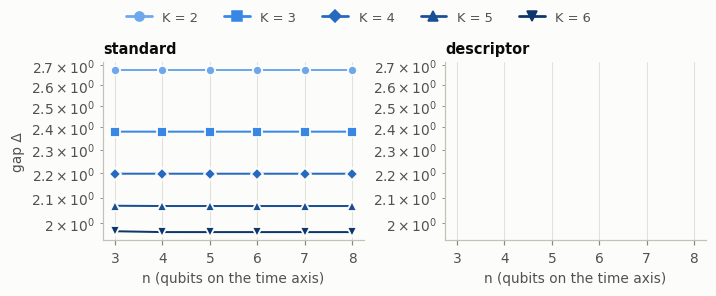

In [4]:
plotting.order_sweep(builds, "gap", "gap Δ");

The minimax filter's degree (T3), a line per order.

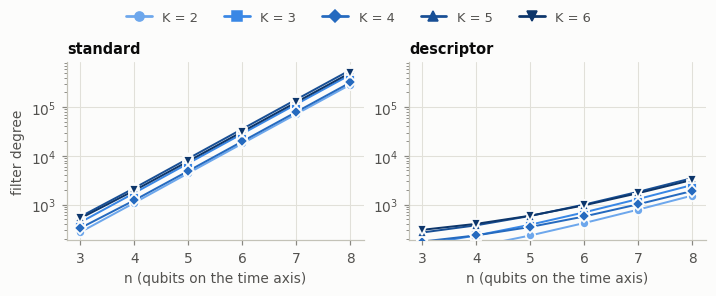

In [5]:
plotting.order_sweep(estimates, "degree", "filter degree");

**What this does not show.** R8 has one field, so its lift is small; the lift of a field on
many modes is notebook 62's. R6's doubled space is built in the standard form only.